In [ ]:
# =============================================================================
# 03_threshold_selection.R
# PH 252 final project — choosing the binary exposure threshold
#
# Exposure (A): share of a municipality's 1994 forest that was cleared by 1999
#               ("loss_frac"), dichotomized at a threshold c:
#                   A = 1 if loss_frac >= c, else 0
#               Only municipalities with at least `min_cover` forest in 1994
#               are eligible (the ratio is unstable when there is little forest).
#
# GOAL: pick (min_cover, c) WITHOUT looking at the dengue outcome.
#   For each candidate pair we compute diagnostics that use only exposure and
#   confounders:
#     1. how many municipalities are exposed (need enough in each group)
#     2. positivity: how many have estimated propensity scores near 0 or 1
#     3. effective sample size after inverse-probability weighting
#     4. covariate balance after weighting (standardized mean differences)
#   Then write down the chosen threshold BEFORE running Part 2, which shows how
#   the effect estimate moves across thresholds as a sensitivity analysis.
#
# Expected folder layout (same as the notes):
#   project/
#   ├── 03_threshold_selection.R      <- this file
#   ├── brazil_dengue_outbreaks_municipality_year.csv
#   └── gee/
#       ├── frag_mapbiomas_1999.csv
#       └── baseline_covariates.csv
#
# Packages: ggplot2 (plots), splines (ships with R).
# Optional for Part 2: sandwich (robust standard errors).
# =============================================================================


In [8]:

library(ggplot2)
library(splines)
library(tidyverse)

# Run from the project folder, or set it here:
# setwd("~/ECOSYS_FRAG_DENGUE")
dir.create("figures", showWarnings = FALSE)



── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ lubridate 1.9.4     ✔ tibble    3.3.0
✔ purrr     1.1.0     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the ]8;;http://conflicted.r-lib.org/conflicted package]8;; to force all conflicts to become errors


Warning message:
package ‘dplyr’ was built under R version 4.5.2 


In [3]:

# -----------------------------------------------------------------------------
# 0. Settings you might want to change
# -----------------------------------------------------------------------------

# Candidate minimum 1994 forest cover (share of municipal land) for eligibility
MIN_COVER_GRID <- c(0.05, 0.10, 0.20, 0.40, 0.50)

# Candidate thresholds on loss_frac (share of 1994 forest lost by 1999)
THRESHOLD_GRID <- c(0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.25)

# Propensity scores below PS_TRIM or above 1 - PS_TRIM count as "extreme"
PS_TRIM <- 0.05

# travel_min_health is from 2019, i.e. AFTER the 1999 exposure. Fragmentation
# can cause road-building, which shortens travel time, so adjusting for it can
# block part of the effect. Leave FALSE for the main analysis and flip to TRUE
# as a sensitivity check.
USE_TRAVEL_TIME <- FALSE



Warning message:
Removed 1 row containing non-finite outside the scale range (`stat_bin()`). 


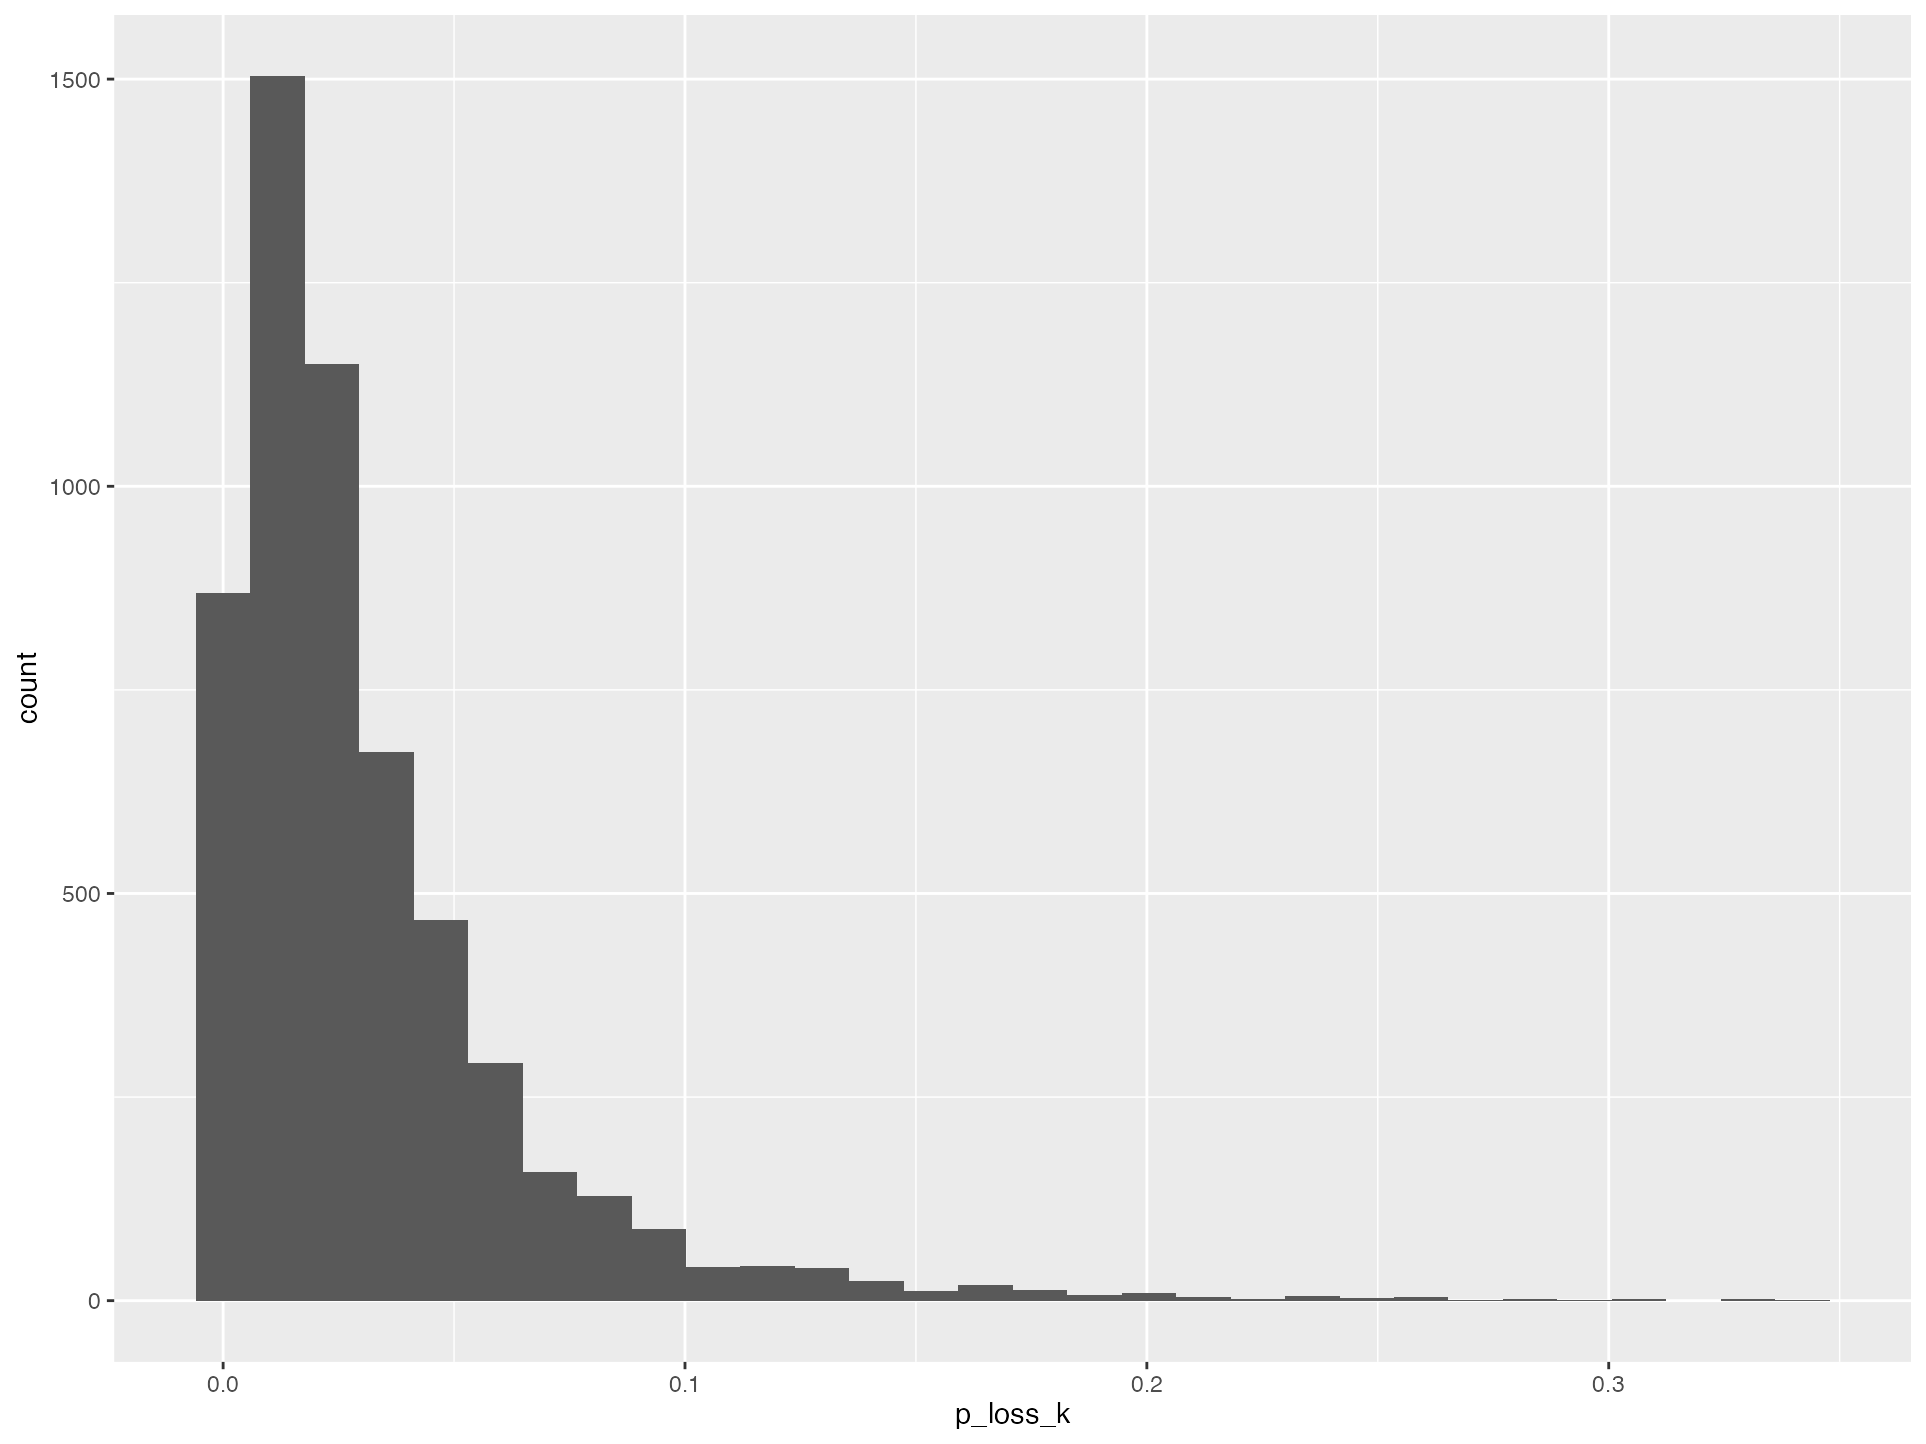

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.

In [10]:

# -----------------------------------------------------------------------------
# 1. Load and merge the exposure and covariate files
# -----------------------------------------------------------------------------

frag <- read.csv("gee/frag_mapbiomas_1999.csv")
base <- read.csv("gee/baseline_covariates.csv")

# IBGE code 430000 is a placeholder for lagoons (it appears twice). Drop it.
frag <- frag[frag$IBGE6 != 430000, ]
base <- base[base$IBGE6 != 430000, ]

dat <- merge(frag, base, by = "IBGE6")

dat %>%
  ggplot(aes(x=p_loss_k)) +
  geom_histogram()

In [16]:

# Region from the first digit of the IBGE code
region_lookup <- c("1" = "North", "2" = "Northeast", "3" = "Southeast",
                   "4" = "South", "5" = "Center-West")
dat$region <- factor(region_lookup[substr(dat$IBGE6, 1, 1)])

# Forest cover in 1994 = forest still standing in 1999 + forest lost 1994–99.
# (Ignores any regrowth during 1994–99; we can't see gains in this file.)
dat$forest_1994 <- dat$p_forest + dat$p_loss_k


In [17]:

# Exposure variable: share of 1994 forest lost by 1999
dat$loss_frac <- dat$p_loss_k / dat$forest_1994

# Log-transform the skewed covariates
dat$log_pop    <- log(dat$pop_2000)
dat$log_travel <- log(dat$travel_min_health)


In [18]:

# Drop rows with any missing value in the variables we use
needed <- c("loss_frac", "forest_1994", "p_urban_1994", "p_pasture_1994",
            "p_agri_1994", "log_pop", "log_travel", "tmean_c_1994_99",
            "precip_mm_yr_1994_99", "elev_m", "region")
dat <- dat[complete.cases(dat[, needed]), ]
cat("Municipalities after cleaning:", nrow(dat), "\n")



Municipalities after cleaning: 5566 


In [19]:

# -----------------------------------------------------------------------------
# 2. Confounders (W) for the propensity score model
# -----------------------------------------------------------------------------
# IMPORTANT: use forest_1994, NOT p_forest (1999). 1999 forest is partly a
# CONSEQUENCE of the exposure (forest_1999 = forest_1994 - loss), so adjusting
# for it would mean adjusting for the exposure itself.
#
# Natural splines (ns) let each continuous confounder have a curved relationship
# with the log-odds of exposure, without us having to guess the shape.

ps_formula <- A ~ ns(forest_1994, 4) + ns(p_urban_1994, 3) +
  ns(p_pasture_1994, 3) + ns(p_agri_1994, 3) + ns(log_pop, 3) +
  ns(tmean_c_1994_99, 3) + ns(precip_mm_yr_1994_99, 3) + ns(elev_m, 3) +
  region

if (USE_TRAVEL_TIME) {
  ps_formula <- update(ps_formula, . ~ . + ns(log_travel, 3))
}

# Covariates to check balance on (raw scale, easier to read)
balance_vars <- c("forest_1994", "p_urban_1994", "p_pasture_1994",
                  "p_agri_1994", "log_pop", "log_travel", "tmean_c_1994_99",
                  "precip_mm_yr_1994_99", "elev_m")



In [20]:

# -----------------------------------------------------------------------------
# 3. Helper functions
# -----------------------------------------------------------------------------

# Standardized mean difference: (mean treated - mean control) / pooled SD.
# Rule of thumb: |SMD| < 0.1 is good balance.
smd <- function(x, a, w = rep(1, length(x))) {
  m1 <- weighted.mean(x[a == 1], w[a == 1])
  m0 <- weighted.mean(x[a == 0], w[a == 0])
  s  <- sqrt((var(x[a == 1]) + var(x[a == 0])) / 2)  # unweighted pooled SD
  (m1 - m0) / s
}

# Kish effective sample size: how many "equally weighted" observations the
# weighted sample is worth. Big drops mean a few units carry huge weights.
ess <- function(w) sum(w)^2 / sum(w^2)

# Fit the propensity model and compute all diagnostics for one (min_cover, c)
evaluate_threshold <- function(min_cover, c) {
  d <- dat[dat$forest_1994 >= min_cover, ]
  d$A <- as.integer(d$loss_frac >= c)

  # Skip combos with almost nobody in one group
  if (sum(d$A) < 30 || sum(1 - d$A) < 30) return(NULL)

  # Propensity score: P(A = 1 | W)
  fit <- glm(ps_formula, data = d, family = binomial)
  ps  <- fitted(fit)

  # Inverse-probability weights for the average treatment effect (ATE)
  w <- ifelse(d$A == 1, 1 / ps, 1 / (1 - ps))

  smd_before <- sapply(balance_vars, function(v) smd(d[[v]], d$A))
  smd_after  <- sapply(balance_vars, function(v) smd(d[[v]], d$A, w))

  data.frame(
    min_cover        = min_cover,
    threshold        = c,
    n_eligible       = nrow(d),
    n_exposed        = sum(d$A),
    pct_exposed      = round(100 * mean(d$A), 1),
    pct_extreme_ps   = round(100 * mean(ps < PS_TRIM | ps > 1 - PS_TRIM), 1),
    max_weight       = round(max(w), 1),
    ess_exposed      = round(ess(w[d$A == 1])),
    ess_unexposed    = round(ess(w[d$A == 0])),
    max_abs_smd_raw  = round(max(abs(smd_before)), 2),
    max_abs_smd_ipw  = round(max(abs(smd_after)), 2),
    # Regions where nearly everyone (or no one) is exposed signal positivity
    # problems that a smooth model might hide
    min_region_pct_exposed = round(100 * min(tapply(d$A, d$region, mean)), 1),
    max_region_pct_exposed = round(100 * max(tapply(d$A, d$region, mean)), 1)
  )
}



In [21]:

# -----------------------------------------------------------------------------
# 4. Run the grid of candidate thresholds  (outcome-blind)
# -----------------------------------------------------------------------------

grid <- expand.grid(min_cover = MIN_COVER_GRID, threshold = THRESHOLD_GRID)
results <- do.call(rbind, mapply(evaluate_threshold,
                                 grid$min_cover, grid$threshold,
                                 SIMPLIFY = FALSE))
results <- results[order(results$min_cover, results$threshold), ]
print(results, row.names = FALSE)
write.csv(results, "threshold_diagnostics.csv", row.names = FALSE)


Warning messages:
1: glm.fit: fitted probabilities numerically 0 or 1 occurred 
2: glm.fit: fitted probabilities numerically 0 or 1 occurred 
3: glm.fit: fitted probabilities numerically 0 or 1 occurred 


 min_cover threshold n_eligible n_exposed pct_exposed pct_extreme_ps max_weight
      0.05     0.050       5302      3420        64.5           10.5       52.6
      0.05     0.075       5302      2327        43.9            9.2       22.2
      0.05     0.100       5302      1544        29.1           14.8       44.6
      0.05     0.125       5302      1017        19.2           25.5       89.5
      0.05     0.150       5302       714        13.5           38.8      230.2
      0.05     0.200       5302       356         6.7           72.3     2246.2
      0.05     0.250       5302       226         4.3           82.4    24073.4
      0.10     0.050       4833      3128        64.7           13.0      104.0
      0.10     0.075       4833      2128        44.0           10.5       25.0
      0.10     0.100       4833      1408        29.1           16.6       42.4
      0.10     0.125       4833       921        19.1           28.4      106.5
      0.10     0.150       4833       64

In [24]:

# How to read the table:
#   pct_exposed       – want a reasonable split (roughly 15–50%)
#   pct_extreme_ps    – lower is better; > ~10% means a real positivity problem
#   ess_*             – compare with n; big drops = unstable estimates
#   max_abs_smd_ipw   – should be < 0.1 after weighting
#   region columns    – a region near 0% or 100% exposed has no comparison group


# -----------------------------------------------------------------------------
# 5. Plots
# -----------------------------------------------------------------------------

# (a) Where the candidate thresholds fall on the exposure distribution
p_hist <- ggplot(dat[dat$forest_1994 >= 0.05, ], aes(x = 100 * loss_frac)) +
  geom_histogram(binwidth = 1, boundary = 0, fill = "grey60") +
  geom_vline(xintercept = 100 * THRESHOLD_GRID, linetype = "dashed",
             colour = "firebrick") +
  coord_cartesian(xlim = c(0, 50)) +
  labs(x = "Share of 1994 forest lost by 1999 (%)",
       y = "Municipalities",
       title = "Exposure distribution with candidate thresholds") +
  theme_minimal()
ggsave("figures/loss_frac_hist_thresholds.png", p_hist, width = 7, height = 4)

# (b) Positivity across thresholds
p_pos <- ggplot(results, aes(x = 100 * threshold, y = pct_extreme_ps,
                             colour = factor(min_cover))) +
  geom_line() + geom_point() +
  labs(x = "Threshold (% of 1994 forest lost)",
       y = paste0("% municipalities with PS < ", PS_TRIM,
                  " or > ", 1 - PS_TRIM),
       colour = "Min 1994\nforest cover",
       title = "Positivity across candidate thresholds") +
  theme_minimal()
ggsave("figures/positivity_by_threshold.png", p_pos, width = 7, height = 4)

# (c) Propensity score overlap for ONE candidate. Edit these two lines.
SHOW_MIN_COVER <- 0.4
SHOW_THRESHOLD <- 0.075

d_show   <- dat[dat$forest_1994 >= SHOW_MIN_COVER, ]
d_show$A <- as.integer(d_show$loss_frac >= SHOW_THRESHOLD)
d_show$ps <- fitted(glm(ps_formula, data = d_show, family = binomial))

p_overlap <- ggplot(d_show, aes(x = ps, fill = factor(A))) +
  geom_histogram(bins = 40, alpha = 0.6, position = "identity") +
  scale_fill_manual(values = c("0" = "steelblue", "1" = "firebrick"),
                    labels = c("Unexposed", "Exposed"), name = NULL) +
  labs(x = "Estimated propensity score P(A = 1 | W)", y = "Municipalities",
       title = sprintf("Overlap: min cover %.2f, threshold %.3f",
                       SHOW_MIN_COVER, SHOW_THRESHOLD)) +
  theme_minimal()
ggsave("figures/ps_overlap_example.png", p_overlap, width = 7, height = 4)

# Same thing split by region: the most honest way to see where overlap fails
ggsave("figures/ps_overlap_by_region.png",
       p_overlap + facet_wrap(~ region, scales = "free_y"),
       width = 9, height = 6)



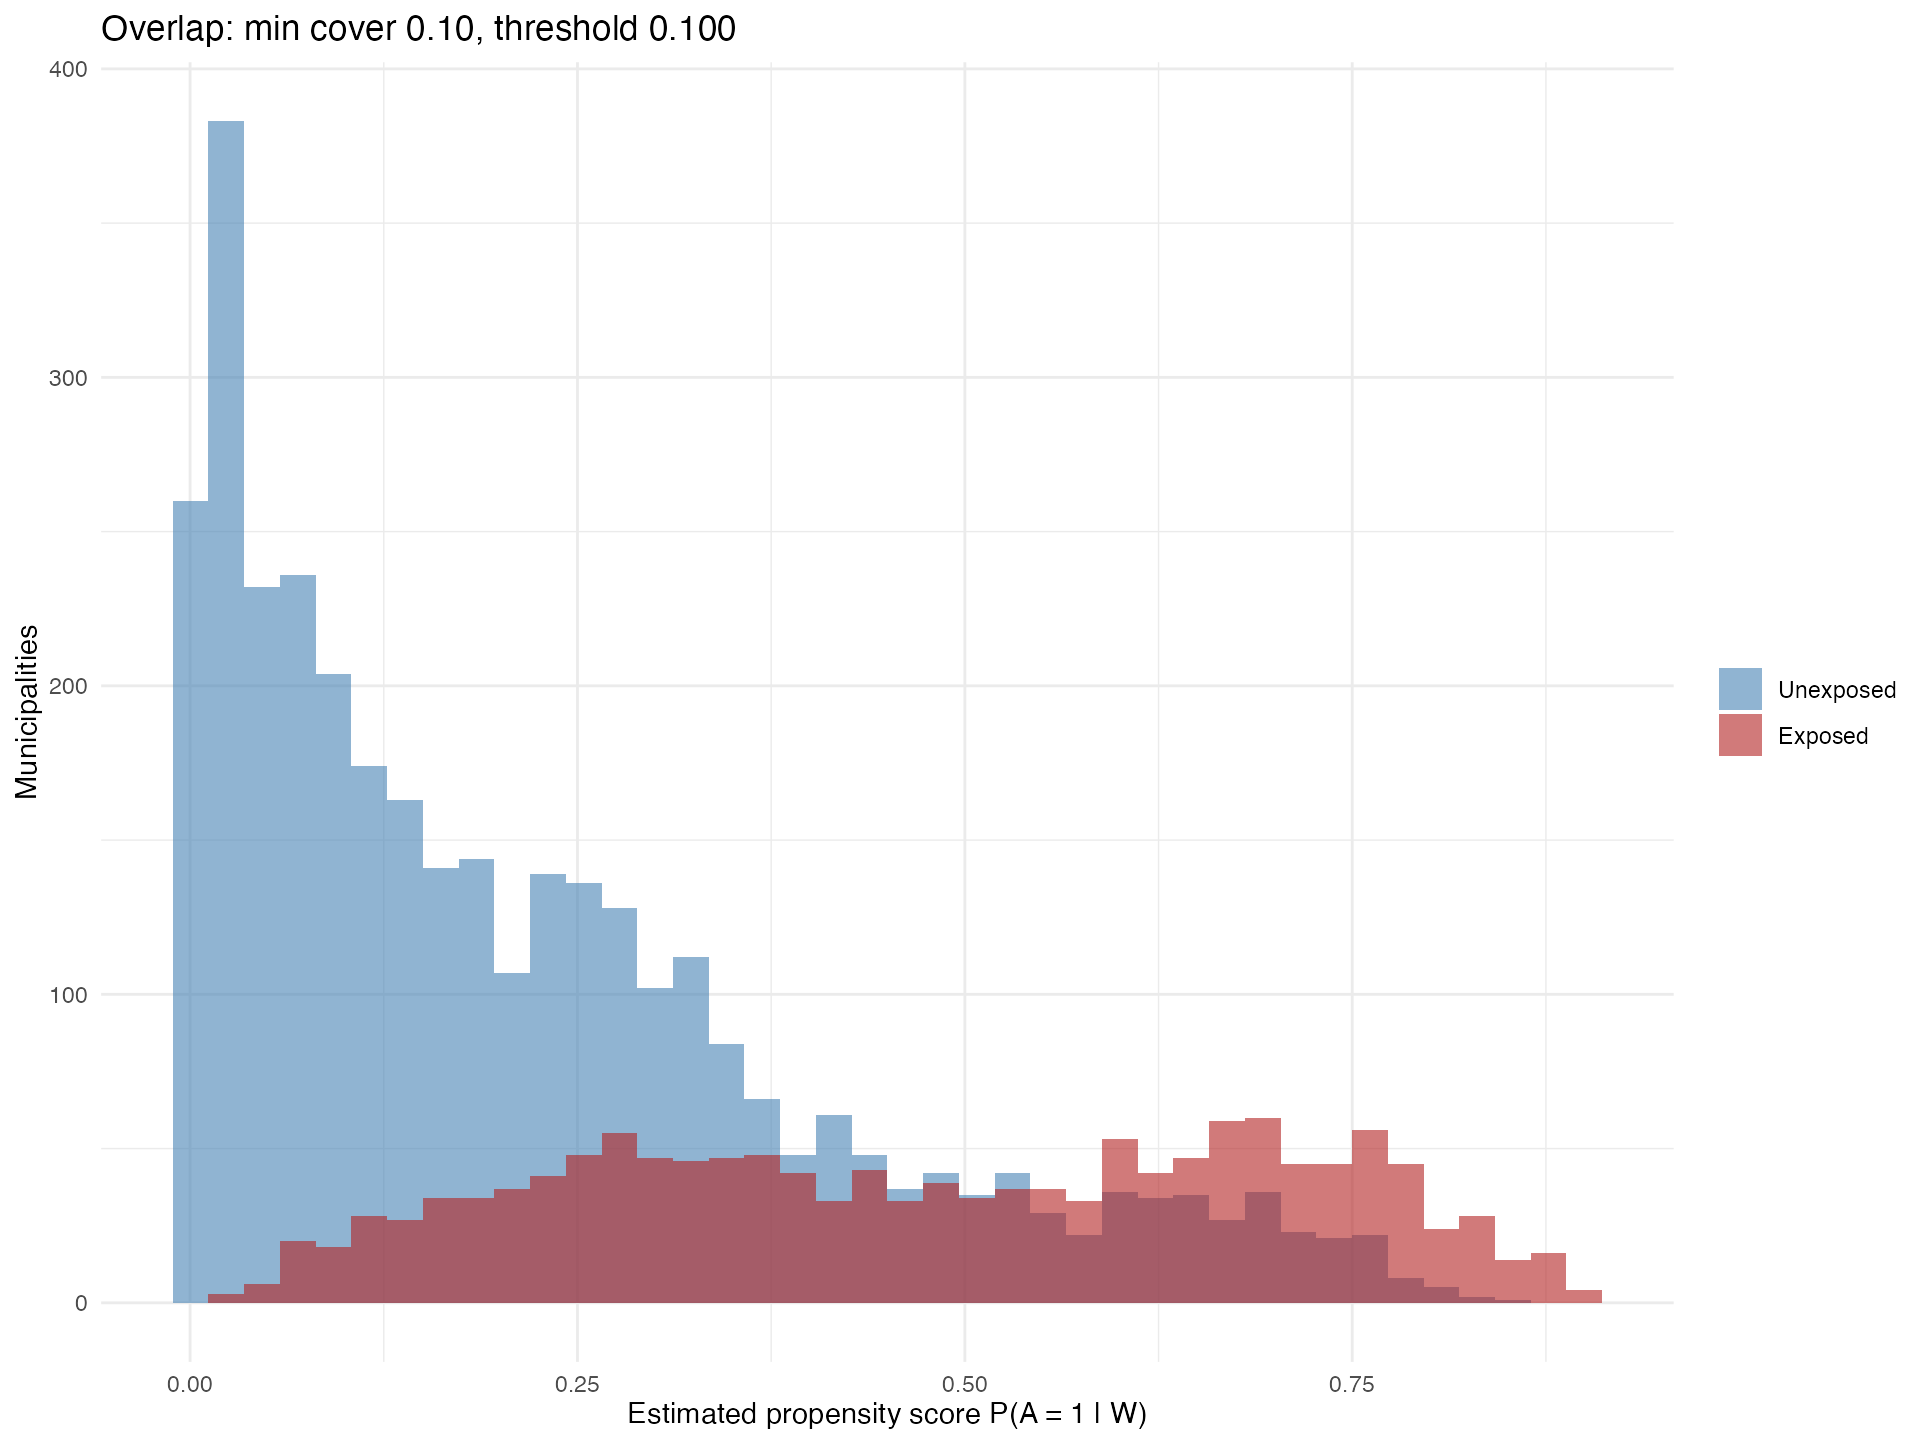

In [23]:
p_overlap

In [ ]:

# =============================================================================
# PART 2 — Sensitivity of the effect estimate to the threshold
# =============================================================================
# Only run this AFTER you have written down your primary (min_cover, c) in the
# project notes. If you pick the threshold by looking at these estimates, the
# confidence intervals no longer mean what they claim to.
#
# Estimator: IPW-weighted Poisson regression of the 2000–2015 outbreak count on
# A. exp(coefficient) = ratio of expected outbreak counts if all eligible
# municipalities were exposed vs. if none were (the ATE on the ratio scale).
# Robust (sandwich) standard errors account for the estimated weights
# conservatively.

RUN_PART_2 <- FALSE

if (RUN_PART_2) {
  library(sandwich)

  # The outcome file is one row per municipality-year. Column names are
  # assumed to be IBGE6, year, n_outbreaks — edit if yours differ.
  outc <- read.csv("brazil_dengue_outbreaks_municipality_year.csv")
  outc <- outc[outc$year >= 2000 & outc$year <= 2015, ]
  y_tot <- aggregate(n_outbreaks ~ IBGE6, data = outc, FUN = sum)
  names(y_tot)[2] <- "Y"

  dat_y <- merge(dat, y_tot, by = "IBGE6", all.x = TRUE)
  dat_y$Y[is.na(dat_y$Y)] <- 0   # no record in the file = no reported outbreak

  estimate_effect <- function(min_cover, c) {
    d <- dat_y[dat_y$forest_1994 >= min_cover, ]
    d$A <- as.integer(d$loss_frac >= c)
    ps <- fitted(glm(ps_formula, data = d, family = binomial))
    d$w <- ifelse(d$A == 1, 1 / ps, 1 / (1 - ps))

    fit <- glm(Y ~ A, data = d, family = quasipoisson, weights = w)
    se  <- sqrt(vcovHC(fit, type = "HC0")["A", "A"])
    b   <- coef(fit)["A"]
    data.frame(min_cover = min_cover, threshold = c,
               rate_ratio = exp(b),
               lo95 = exp(b - 1.96 * se), hi95 = exp(b + 1.96 * se))
  }

  sens <- do.call(rbind, mapply(estimate_effect,
                                results$min_cover, results$threshold,
                                SIMPLIFY = FALSE))
  print(sens, row.names = FALSE, digits = 3)
  write.csv(sens, "threshold_sensitivity_estimates.csv", row.names = FALSE)

  p_sens <- ggplot(sens, aes(x = 100 * threshold, y = rate_ratio,
                             ymin = lo95, ymax = hi95,
                             colour = factor(min_cover))) +
    geom_hline(yintercept = 1, linetype = "dashed") +
    geom_pointrange(position = position_dodge(width = 1)) +
    scale_y_log10() +
    labs(x = "Threshold (% of 1994 forest lost)",
         y = "Outbreak rate ratio (exposed vs unexposed), log scale",
         colour = "Min 1994\nforest cover",
         title = "Sensitivity of the estimate to the threshold") +
    theme_minimal()
  ggsave("figures/estimate_by_threshold.png", p_sens, width = 7, height = 4)
}